# 📘 Machine Learning 2026/2027  

## Laboratorio 4.1 — Regressione Lineare, Gradient Descent e Regolarizzazione  
## Docenti: Danilo Croce, Giorgio Gambosi  

In questo laboratorio esploriamo **l’intero percorso della regressione lineare**, partendo dalle basi fino alle versioni regolarizzate (*Ridge* e *Lasso*), passando attraverso la **discesa del gradiente**.  

L’obiettivo è stimare una funzione non lineare (una sinusoide) a partire da pochi punti **rumorosi**, e comprendere come la complessità del modello e la regolarizzazione influenzino il risultato.

---

## 🎯 Obiettivi didattici

1. **Comprendere la regressione lineare come modello base** di apprendimento supervisionato.  
2. **Costruire la matrice di design polinomiale** per trasformare un problema non lineare in uno lineare nei parametri.  
3. **Derivare e implementare la soluzione analitica** ai minimi quadrati:
   $$
   w^* = (\Phi^\top \Phi)^{-1} \Phi^\top t.
   $$
4. **Implementare la discesa del gradiente (Gradient Descent)** e confrontarla con la soluzione chiusa.  
5. **Osservare il trade-off bias–varianza** al variare del grado polinomiale $M$.  
6. **Introdurre la regolarizzazione L2 (Ridge)** e L1 (Lasso) per evitare overfitting e ottenere modelli più stabili.  

---

## 📚 Struttura del notebook

| Sezione | Contenuto |
|----------|------------|
| **1. Setup e dataset** | Generazione dei dati rumorosi da una sinusoide. |
| **2. Matrice di design polinomiale** | Costruzione della base $[1, x, x^2, …, x^M]$. |
| **3. Regressione ai minimi quadrati (forma chiusa)** | Derivazione e implementazione della soluzione analitica. |
| **4. Gradient Descent** | Approccio iterativo alla minimizzazione del costo. |
| **5. Ridge Regression** | Regolarizzazione L2 — soluzione analitica e iterativa. |
| **6. Lasso Regression** | Regolarizzazione L1 e confronto qualitativo. |
| **7. Regressione con scikit-learn** | Mostriamo come utilizzare la libreria `scikit-learn` per implementare in modo semplice le stesse tecniche  |
---

### 🧩 Setup e Dataset

In questa prima sezione costruiamo il **dataset sintetico** su cui lavoreremo per tutto il laboratorio.

Simuliamo un esperimento di regressione in cui i dati sono generati da una **funzione sinusoidale**:

$$
t = \sin(2\pi x) + \varepsilon, \quad \varepsilon \sim \mathscr{N}(0, \sigma^2),
$$

dove $ \varepsilon $ rappresenta un **rumore gaussiano** che introduce incertezza nelle osservazioni.  

---

### 🎯 Obiettivo

Il nostro scopo è ricostruire la funzione sottostante (la sinusoide “vera”) partendo da pochi punti rumorosi, analizzando:

1. **Come la complessità del modello** (grado polinomiale $M$) influisce sulla qualità del fit.  
2. **Come diversi metodi di ottimizzazione** — forma chiusa, *gradient descent*, e regolarizzazioni (*Ridge* e *Lasso*) — modificano la soluzione.  
3. **Come la normalizzazione dei dati** aiuta la stabilità numerica.

---

### ⚙️ Cosa fa il codice seguente

- Genera un piccolo **training set** (15 punti) rumoroso.  
- Crea un **test set denso** per visualizzare la funzione continua.  
- Aggiunge rumore gaussiano per simulare misure reali.  
- Normalizza le feature per evitare instabilità nei calcoli.  
- Visualizza graficamente i punti campionati rispetto alla funzione vera $ \sin(2\pi x) $.

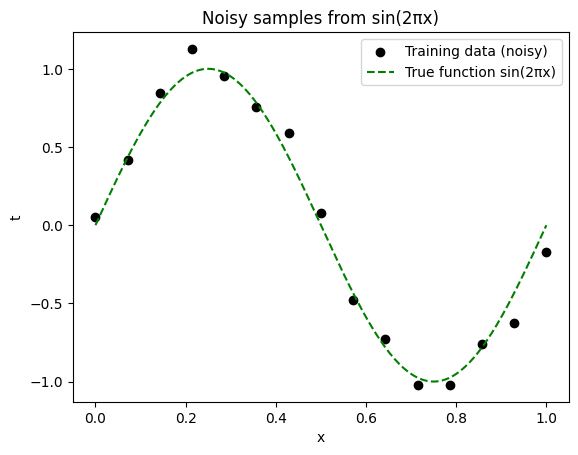

In [ ]:
# %%
# ============================================================
# LINEAR REGRESSION on a noisy sine function
# From least squares → gradient descent → ridge → lasso
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, Lasso

# Impostiamo il seed per rendere i risultati riproducibili
np.random.seed(42)

# ------------------------------------------------------------
# 1️⃣  Generazione del dataset
# ------------------------------------------------------------

# Numero di punti nel training set (pochi, per rendere il problema ambiguo)
n_train = 15

# Numero di punti per il test (molti, per valutare il modello su tutto l'intervallo)
n_test = 200

# Deviazione standard del rumore gaussiano
sigma = 0.1

# Punti di training equispaziati tra 0 e 1
X_train = np.linspace(0, 1, n_train).reshape(-1, 1)

# Funzione di verità: sin(2πx)
# Aggiungiamo un rumore gaussiano ~ N(0, σ²)
# → simula dati sperimentali "realistici" (non perfettamente puliti)
t_train = np.sin(2 * np.pi * X_train) + np.random.normal(0, sigma, X_train.shape)

# Griglia densa per visualizzare la funzione e valutare
# quanto bene il modello ricostruisce il segnale vero.
#
# ATTENZIONE: non è un test set indipendente con target rumorosi.
# È una griglia di valutazione sintetica, sulla quale conosciamo
# esattamente la funzione generatrice.

X_test = np.linspace(0, 1, n_test).reshape(-1, 1)
t_test = np.sin(2 * np.pi * X_test)

# Manteniamo i nomi X_test e t_test per compatibilità
# con tutte le celle successive.

# ------------------------------------------------------------
# 2️⃣  Normalizzazione delle feature
# ------------------------------------------------------------

# Centriamo e scaliamo X per evitare problemi di overflow/underflow
# (soprattutto per polinomi di grado elevato)
X_mean, X_std = np.mean(X_train), np.std(X_train)
X_train_n = (X_train - X_mean) / X_std
X_test_n = (X_test - X_mean) / X_std

# ------------------------------------------------------------
# 3️⃣  Visualizzazione dei dati
# ------------------------------------------------------------

plt.scatter(X_train, t_train, color="black", label="Training data (noisy)")
plt.plot(X_test, t_test, "g--", label="True function sin(2πx)")
plt.legend()
plt.title("Noisy samples from sin(2πx)")
plt.xlabel("x")
plt.ylabel("t")
plt.show()

### 📌 Nota sulla valutazione

In questo laboratorio utilizziamo un dataset sintetico, per il quale conosciamo la funzione generatrice $f(x)=\sin(2\pi x)$.

La griglia `X_test` e i corrispondenti valori `t_test` vengono utilizzati per misurare **l'errore di ricostruzione della funzione vera**, non l'errore su nuove osservazioni rumorose.

In un problema reale non conosciamo la funzione generatrice: utilizziamo un *validation set* per scegliere gli iperparametri e un *test set* indipendente per valutare il modello finale.

Nel nostro caso, la conoscenza della funzione vera ci permette di studiare direttamente gli effetti di complessità e regolarizzazione.

## 🧮 Matrice delle feature polinomiali

Per poter applicare la regressione lineare a un problema *non lineare* (come la nostra sinusoide), costruiamo una **base polinomiale** dei dati di input.

Ogni punto $x_i$ viene trasformato in un vettore di potenze:

$$
\phi(x_i) = [\,1,\, x_i,\, x_i^2,\, \dots,\, x_i^M\,],
$$

dove $M$ è il **grado del polinomio** scelto.

Raggruppando tutte le $n$ osservazioni otteniamo la **matrice di progetto** (*design matrix*):

$$
\Phi =
\begin{bmatrix}
1 & x_1 & x_1^2 & \cdots & x_1^M \\
1 & x_2 & x_2^2 & \cdots & x_2^M \\
\vdots & \vdots & \vdots & & \vdots \\
1 & x_n & x_n^2 & \cdots & x_n^M
\end{bmatrix}
\in \mathbb{R}^{n\times (M+1)}.
$$

Ogni colonna rappresenta un “livello di complessità” del modello:
- la prima (tutta 1) serve per il **bias** $b$;
- le successive corrispondono ai termini $x$, $x^2$, $\dots$, $x^M$.

In Python, questa costruzione può essere fatta comodamente con `np.hstack`:

In [ ]:
# %%
def polynomial_design_matrix(X, M):
    """Ritorna la matrice delle feature [1, x, x^2, ..., x^M]."""
    return np.hstack([X**i for i in range(M + 1)])

## 🎯 Regressione ai Minimi Quadrati — Soluzione Analitica

Una volta costruita la matrice delle feature $\Phi$,  
il modello polinomiale diventa **lineare nei parametri**:

$$
y = \Phi w,
$$

dove:
- $\Phi \in \mathbb{R}^{n\times (M+1)}$ è la *design matrix* (ogni riga è $\phi(x_i)$),
- $w \in \mathbb{R}^{M+1}$ contiene il bias e i coefficienti polinomiali,
- $t \in \mathbb{R}^{n}$ rappresenta i valori target osservati.

---

### 🔹 Funzione di costo (Errore Quadratico Medio)

Definiamo il costo come **media dei quadrati dei residui**:

$$
E(w) = \frac{1}{2n}\|\Phi w - t\|^2
= \frac{1}{2n}(\Phi w - t)^\top(\Phi w - t),
$$

dove il fattore $\tfrac{1}{2n}$ è solo una convenzione utile per semplificare le derivate.

---

### 🔹 Derivata rispetto ai pesi

Richiamiamo la regola generale:

$$
\nabla_u\,\frac{1}{2}\|A u - b\|^2 = A^\top(Au - b).
$$

Applicandola con $A=\Phi$, $u=w$ e $b=t$, otteniamo:

$$
\nabla_w E(w) = \frac{1}{n}\,\Phi^\top(\Phi w - t).
$$

---

### 🔹 Condizione di minimo

Per trovare il punto stazionario imponiamo che il gradiente sia nullo:

$$
\nabla_w E(w) = 0
\quad \Longrightarrow \quad
\Phi^\top(\Phi w - t) = 0.
$$

Da cui segue:

$$
\Phi^\top \Phi w = \Phi^\top t.
$$

Questa è la **forma normale** (*normal equation*), un sistema lineare in $w$.

---

### 🔹 Soluzione in forma chiusa

Se $\Phi^\top\Phi$ è invertibile (colonne linearmente indipendenti), la soluzione ottimale è:

$$
\boxed{w^\ast = (\Phi^\top\Phi)^{-1}\Phi^\top t.}
$$

Se invece $\Phi^\top\Phi$ è singolare (ad esempio quando $M+1 > n$), si utilizza la **pseudoinversa di Moore–Penrose**:

$$
w^\ast = \Phi^{+}t.
$$

---

### 🔹 Interpretazione

- $\Phi^\top\Phi$ rappresenta la **correlazione** tra le colonne (feature).  
- $\Phi^\top t$ è la **proiezione dei target** sullo spazio generato dalle feature.  
- L’equazione $(\Phi^\top\Phi)w=\Phi^\top t$ individua il vettore $w$ che  
  **minimizza la somma dei quadrati degli errori** tra le predizioni $\Phi w$ e i valori reali $t$.

---

📘 In sintesi: la regressione ai minimi quadrati trova la retta (o curva polinomiale)  
che approssima al meglio i dati nel senso dei minimi quadrati, fornendo una soluzione chiusa e diretta al problema di apprendimento.

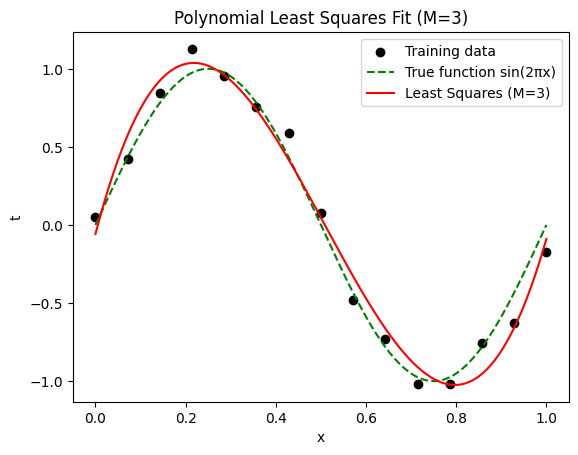

In [ ]:
# ============================================================
# POLYNOMIAL LEAST SQUARES — NUMERICALLY STABLE SOLUTION
# ============================================================
# Obiettivo:
#   Calcolare i coefficienti ottimali della regressione
#   polinomiale ai minimi quadrati.
#
# La teoria ci fornisce le equazioni normali:
#
#   (Phi.T @ Phi) @ w = Phi.T @ t
#
# Tuttavia costruire esplicitamente Phi.T @ Phi può
# peggiorare la stabilità numerica, soprattutto quando
# le colonne della matrice di design sono molto correlate.
#
# Usiamo quindi np.linalg.lstsq(), che risolve direttamente
# il problema dei minimi quadrati senza calcolare l'inversa.
# ============================================================

def fit_least_squares(X, t, M):
    """
    Stima i coefficienti ottimali della regressione
    polinomiale tramite Ordinary Least Squares (OLS).

    Problema:
        min_w ||Phi @ w - t||²

    Parametri:
        X : input normalizzati, dimensione (n, 1)
        t : valori target, dimensione (n, 1)
        M : grado massimo del polinomio

    Restituisce:
        w   : coefficienti stimati, dimensione (M+1, 1)
        Phi : matrice di design, dimensione (n, M+1)

    Nota:
        Se Phi ha rango pieno, la soluzione è unica.
        In caso di rango insufficiente, lstsq restituisce
        una soluzione ai minimi quadrati di norma minima.
    """

    # --------------------------------------------------------
    # 1️⃣  Costruzione della matrice delle feature polinomiali
    # --------------------------------------------------------
    # Ogni riga contiene:
    # [1, x_i, x_i², ..., x_i^M]
    Phi = polynomial_design_matrix(X, M)

    # --------------------------------------------------------
    # 2️⃣  Risoluzione del problema dei minimi quadrati
    # --------------------------------------------------------
    # np.linalg.lstsq risolve:
    #
    #     min_w ||Phi @ w - t||²
    #
    # Senza costruire esplicitamente la matrice Phi.T @ Phi.
    #
    # I valori aggiuntivi restituiti descrivono i residui,
    # il rango numerico e i valori singolari di Phi.
    w, residuals, rank, singular_values = np.linalg.lstsq(
        Phi, t, rcond=None
    )

    # --------------------------------------------------------
    # 3️⃣  Restituzione del modello stimato
    # --------------------------------------------------------
    return w, Phi



# ============================================================
# POLYNOMIAL REGRESSION — PREDICTION
# ============================================================
# Obiettivo:
#   Utilizzare i coefficienti appresi per generare
#   predizioni su nuovi punti.
#
# Il modello è:
#
#   y = Phi @ w
#
# Il grado polinomiale viene ricavato automaticamente
# dal numero dei coefficienti.
# ============================================================

def predict(X, w):
    """
    Calcola le predizioni di un modello polinomiale.

    Parametri:
        X : input normalizzati, dimensione (n, 1)
        w : coefficienti, dimensione (M+1, 1)

    Restituisce:
        y : predizioni, dimensione (n, 1)
    """

    # --------------------------------------------------------
    # 1️⃣  Ricaviamo il grado dal numero dei coefficienti
    # --------------------------------------------------------
    M = len(w) - 1

    # --------------------------------------------------------
    # 2️⃣  Costruiamo la matrice di design
    # --------------------------------------------------------
    Phi = polynomial_design_matrix(X, M)

    # --------------------------------------------------------
    # 3️⃣  Calcoliamo le predizioni
    # --------------------------------------------------------
    return Phi @ w



# ------------------------------------------------------------
# 1️⃣  Esempio singolo: M = 3
# ------------------------------------------------------------

M = 3
w_ls, Phi_train = fit_least_squares(X_train_n, t_train, M)
y_ls = predict(X_test_n, w_ls)

plt.scatter(X_train, t_train, color="black", label="Training data")
plt.plot(X_test, t_test, "g--", label="True function sin(2πx)")
plt.plot(X_test, y_ls, "r", label=f"Least Squares (M={M})")
plt.legend()
plt.title("Polynomial Least Squares Fit (M=3)")
plt.xlabel("x")
plt.ylabel("t")
plt.show()

### 🔍 Polynomial Fits for Multiple Degrees $ M $

In questa sezione osserviamo **come cambia la complessità del modello** aumentando il grado polinomiale $ M $ nella regressione ai minimi quadrati.

Partendo da pochi punti rumorosi generati da $ \sin(2\pi x) $, costruiamo modelli polinomiali di gradi diversi e confrontiamo le curve risultanti:

$$
y(x) = \sum_{j=0}^{M} w_j x^j = w_0 + w_1 x + w_2 x^2 + \dots + w_M x^M
$$

Per ciascun $ M $:

1. Costruiamo la **matrice di design** $ \Phi = [1, x, x^2, \dots, x^M] $.
2. Calcoliamo i pesi ottimali $ w = (\Phi^\top \Phi)^{-1} \Phi^\top t $.
3. Visualizziamo la curva ottenuta insieme ai dati e alla funzione vera.

---


=== Mean Squared Error (MSE) ===
Grado M	Train MSE	Test MSE
----------------------------------
0      	0.5230	0.4975
1      	0.2411	0.2018
3      	0.0112	0.0120
5      	0.0042	0.0038
9      	0.0024	0.0075
12     	0.0005	0.0339


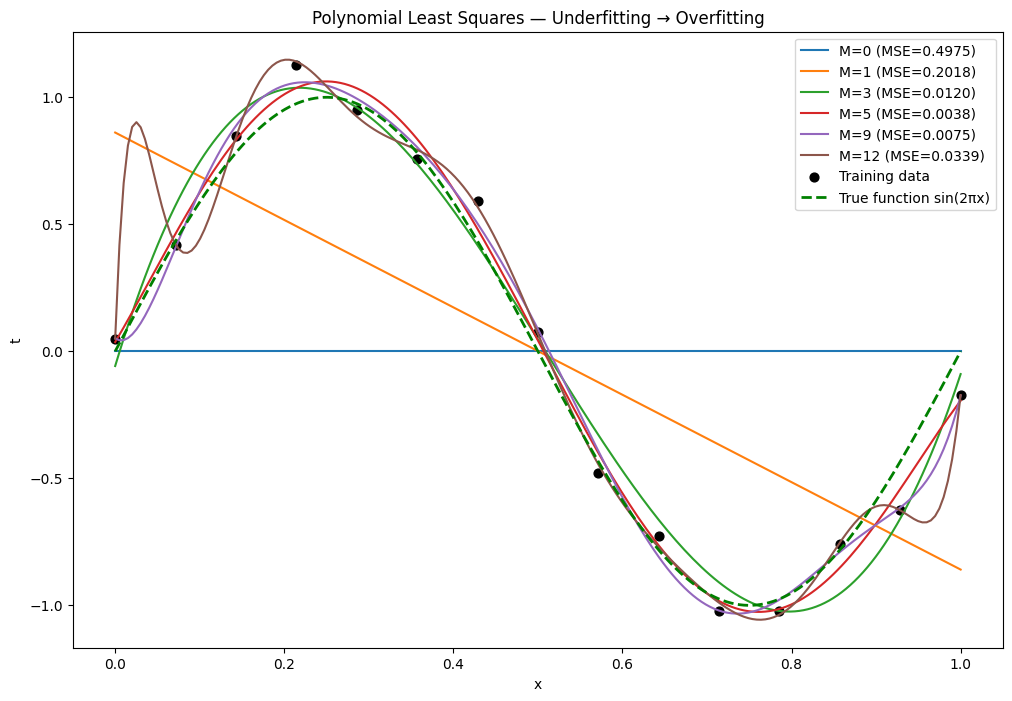

In [ ]:
# %%
# ============================================================
# 2️⃣  POLYNOMIAL FITS FOR MULTIPLE DEGREES M + MSE
# ============================================================

from sklearn.metrics import mean_squared_error

degrees = [0, 1, 3, 5, 9, 12]  # diversi gradi di complessità

plt.figure(figsize=(12, 8))

print("=== Mean Squared Error (MSE) ===")
print("Grado M\tTrain MSE\tTest MSE")
print("----------------------------------")

for M in degrees:
    # Fit del modello ai minimi quadrati
    w_ls, Phi_train = fit_least_squares(X_train_n, t_train, M)

    # Predizioni su train e test
    y_train_pred = predict(X_train_n, w_ls)
    y_test_pred  = predict(X_test_n, w_ls)

    # Calcolo MSE
    mse_train = mean_squared_error(t_train, y_train_pred)
    mse_test  = mean_squared_error(t_test, y_test_pred)

    # Stampa tabellina dei risultati
    print(f"{M:<7d}\t{mse_train:.4f}\t{mse_test:.4f}")

    # Tracciamento del modello
    plt.plot(X_test, y_test_pred, label=f"M={M} (MSE={mse_test:.4f})")

# Dati e funzione vera
plt.scatter(X_train, t_train, color="black", s=40, label="Training data")
plt.plot(X_test, t_test, "g--", linewidth=2, label="True function sin(2πx)")

plt.legend()
plt.title("Polynomial Least Squares — Underfitting → Overfitting")
plt.xlabel("x")
plt.ylabel("t")
plt.show()

#### 💡 Cosa osservare nel grafico

- **Basso grado (M = 0, 1)** →  
  La curva è troppo semplice: non riesce a seguire la forma sinusoidale.  
  → **Underfitting**: alto bias, errore sistematico.

- **Grado medio (M = 3–5)** →  
  Il modello segue bene l’andamento della sinusoide senza oscillare.  
  → Buon compromesso bias–varianza.

- **Grado alto (M = 9, 12)** → Il modello diventa molto flessibile e può adattarsi anche al rumore dei dati, producendo oscillazioni e peggiorando l'errore di ricostruzione della funzione vera.

**Attenzione:** con 15 osservazioni e ascisse distinte, un polinomio di grado 14 possiede 15 coefficienti e può interpolare esattamente tutti i punti di training. Un polinomio di grado 9 o 12 non garantisce invece un'interpolazione esatta.

L'overfitting può manifestarsi anche prima di raggiungere l'interpolazione perfetta.
---

### 📈 Conclusione

Aumentando il grado \(M\), il modello diventa più flessibile e può adattarsi sempre meglio ai dati di training, compreso il rumore.

Con un grado troppo basso osserviamo **underfitting**; con un grado elevato possiamo osservare **overfitting**, cioè un buon adattamento ai dati di training ma una cattiva ricostruzione della funzione vera.

Questo comportamento è collegato al **trade-off bias–varianza**, ma un singolo training set non permette di misurare direttamente la varianza del predittore.

Per osservare la varianza dovremmo ripetere l'addestramento su molti training set indipendenti e confrontare quanto cambiano le curve ottenute.

---

## ⚙️ Polynomial Regression — Gradient Descent Implementation

Finora abbiamo risolto la regressione polinomiale **in forma chiusa**, con la classica soluzione ai minimi quadrati:

$$
w^\ast = (\Phi^\top \Phi)^{-1} \Phi^\top t.
$$

Ora affrontiamo lo stesso problema **in modo iterativo**, usando la **Discesa del Gradiente (Gradient Descent)**, che aggiorna progressivamente i parametri per ridurre l’errore.

---

### 🔹 1️⃣ Funzione di costo

Definiamo la funzione di costo come l’**errore quadratico medio (MSE)**:

$$
E(w) = \frac{1}{2n} \|\Phi w - t\|^2
     = \frac{1}{2n}(\Phi w - t)^\top(\Phi w - t).
$$

Il fattore $\tfrac{1}{2n}$ è solo una costante di normalizzazione utile per semplificare le derivate.

---

### 🔹 2️⃣ Gradiente rispetto a $w$

Vogliamo calcolare il gradiente della funzione di costo:

$$
E(w)=\frac{1}{2n}\|\Phi w-t\|^2.
$$

**Partiamo sviluppando il quadrato**, come facciamo normalmente con $(a-b)^2=a^2-2ab+b^2$.

In forma matriciale otteniamo:

$$
E(w)=\frac{1}{2n}
\left(
w^\top\Phi^\top\Phi w
-2t^\top\Phi w
+t^\top t
\right).
$$

Abbiamo quindi tre termini, che possiamo derivare separatamente rispetto ai pesi $w$.

**1. Primo termine:**

$$
\nabla_w\left(\frac{1}{2n}w^\top\Phi^\top\Phi w\right)
=\frac{1}{n}\Phi^\top\Phi w.
$$

Questo è analogo alla derivata di $\frac12 aw^2$, che è $aw$. In questo caso, al posto del numero $a$ abbiamo la matrice simmetrica $\Phi^\top\Phi$.

**2. Secondo termine:**

$$
\nabla_w\left(-\frac{1}{n}t^\top\Phi w\right)
=-\frac{1}{n}\Phi^\top t.
$$

Qui $w$ compare una sola volta: derivando, rimane il vettore che lo moltiplica.

**3. Terzo termine:**

$$
\nabla_w\left(\frac{1}{2n}t^\top t\right)=0.
$$

Questo termine contiene soltanto i target $t$, quindi non cambia al variare dei pesi $w$.

**Sommiamo le tre derivate:**

$$
\nabla_w E(w)
=
\frac{1}{n}\Phi^\top\Phi w
-\frac{1}{n}\Phi^\top t.
$$

Raccogliendo $\frac{1}{n}\Phi^\top$, otteniamo:

$$
\boxed{
\nabla_w E(w)=\frac{1}{n}\Phi^\top(\Phi w-t)
}
$$

Questa è la formula del gradiente che utilizzeremo nel Gradient Descent.

---

### 🔹 3️⃣ Aggiornamento iterativo

Ad ogni passo $k$:

$$
w^{(k+1)} = w^{(k)} - \eta \, \nabla_w E(w^{(k)}),
$$

ossia:

$$
w^{(k+1)} = w^{(k)} - \frac{\eta}{n}\Phi^\top(\Phi w^{(k)} - t),
$$

dove $\eta$ è il **learning rate**, cioè la dimensione del passo di aggiornamento.

---

### 🔹 4️⃣ Interpretazione intuitiva

- $(\Phi w - t)$ è il vettore dei **residui** (gli errori di predizione).  
- $\Phi^\top(\Phi w - t)$ calcola quanto questi errori sono **correlati con ciascuna feature**.  
- Aggiornando $w$ nella direzione opposta, il modello “raddrizza” progressivamente la previsione finché il gradiente si annulla.

---

### 🔹 5️⃣ Convergenza e minimo

Quando il gradiente diventa nullo:

$$
\nabla_w E(w^\ast) = 0
\;\;\Rightarrow\;\;
\Phi^\top(\Phi w^\ast - t) = 0,
$$

che è **esattamente** la condizione dei **minimi quadrati**:

$$
(\Phi^\top \Phi)w^\ast = \Phi^\top t.
$$

---

### 🔹 6️⃣ Considerazioni pratiche

| Caso | Effetto |
|------|----------|
| $\eta$ troppo grande | Il costo oscilla o diverge |
| $\eta$ troppo piccolo | Converge molto lentamente |
| Valore ideale | Diminuzione rapida ma stabile di $E(w)$ |

Il grafico “**Costo vs Iterazione**” mostra tipicamente una discesa rapida iniziale, poi un plateau vicino al minimo.

---

### 💡 In sintesi

| Concetto | Formula | Significato |
|-----------|----------|-------------|
| Funzione di costo | $${E(w) = \tfrac{1}{2n}\|\Phi w - t\|^2}$$ | Errore medio quadratico |
| Gradiente | $$\nabla_w E(w) = \tfrac{1}{n}\Phi^\top(\Phi w - t)$$ | Direzione di massima crescita |
| Aggiornamento | $$w \leftarrow w - \eta \nabla_w E(w)$$ | Passo verso il minimo |
| Condizione di minimo | $$\Phi^\top(\Phi w^\ast - t)=0$$ | Coincide con la soluzione ai minimi quadrati |

---

### 🔹 7️⃣ Collegamento al codice

Nel notebook, implementiamo:
- `cost()` → calcola $E(w)$  
- `grad()` → calcola $\nabla_w E(w)$  
- `gradient_descent()` → aggiorna $w$ iterativamente  

Alla fine, $w$ converge alla stessa soluzione analitica,  
ma ottenuta **tramite aggiornamenti incrementali**, come nei moderni algoritmi di *deep learning*.

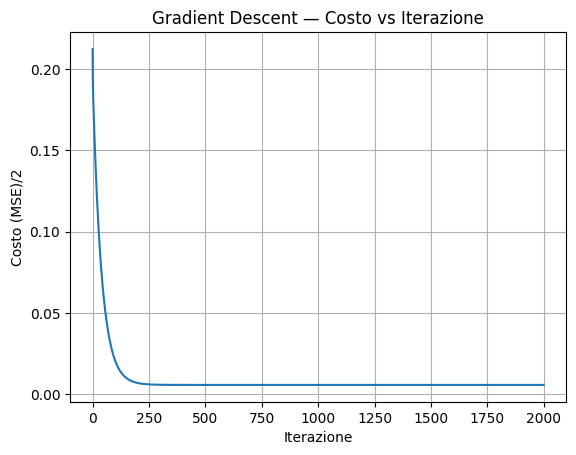

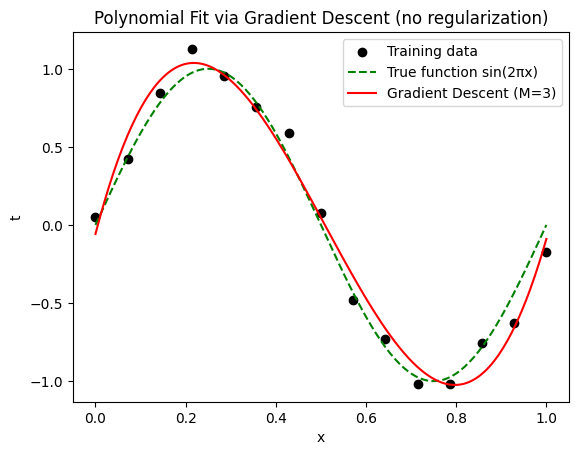

In [ ]:
# %%
# ============================================================
# POLYNOMIAL REGRESSION — GRADIENT DESCENT (BATCH FORM)
# ============================================================
# Obiettivo:
#   Approssimare una funzione (sinusoidale) usando regressione polinomiale
#   con ottimizzazione iterativa tramite discesa del gradiente.
#
#   In questa versione il gradiente è calcolato su TUTTO il dataset
#   → "Batch Gradient Descent".
#   Le versioni "Stochastic" e "Mini-Batch" sono varianti che usano
#   rispettivamente un solo campione o un sottoinsieme a ogni passo.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1️⃣  Funzione di costo (Mean Squared Error)
# ------------------------------------------------------------
def cost(Phi, w, t):
    """
    Calcola la funzione di costo:
        E(w) = 1/(2n) * ||Φw - t||²
    dove:
        Φ : matrice di design (n × M+1)
        w : vettore dei pesi (M+1 × 1)
        t : target (n × 1)
    """
    r = Phi @ w - t        # residui = differenza tra predizioni e valori reali
    return 0.5 * np.mean(r**2)


# ------------------------------------------------------------
# 2️⃣  Gradiente della funzione di costo
# ------------------------------------------------------------
def grad(Phi, w, t):
    """
    Calcola il gradiente del costo rispetto ai pesi:
        ∇E(w) = (1/n) * Φᵀ(Φw - t)
    che indica la direzione di massima crescita del costo.
    """
    r = Phi @ w - t
    return (Phi.T @ r) / len(t)


# ------------------------------------------------------------
# 3️⃣  Discesa del gradiente (Batch)
# ------------------------------------------------------------
def gradient_descent(Phi, t, eta=1e-2, epochs=5000):
    """
    Esegue la discesa del gradiente batch:
        w ← w - η ∇E(w)
    per un numero prefissato di iterazioni.

    Non implementa un criterio di arresto anticipato
    basato sulla convergenza.

    Parametri:
        Phi    : matrice di design (n × M+1)
        t      : vettore target (n × 1)
        eta    : learning rate (controlla l’ampiezza del passo)
        epochs : numero di iterazioni di aggiornamento

    Ritorna:
        w      : pesi appresi
        costs  : lista dei valori di E(w) nel tempo
    """
    # Inizializzazione dei pesi (tutti a zero)
    w = np.zeros((Phi.shape[1], 1))
    costs = []

    # Ciclo di ottimizzazione
    for _ in range(epochs):
        # Calcolo del gradiente completo (su tutti i dati)
        g = grad(Phi, w, t)
        # Aggiornamento dei pesi
        w -= eta * g
        # Calcolo e memorizzazione del costo corrente
        costs.append(cost(Phi, w, t))

    return w, costs


# ------------------------------------------------------------
# 4️⃣  Applicazione: POLINOMIO DI GRADO M = 3
# ------------------------------------------------------------
M = 3
Phi_train = polynomial_design_matrix(X_train_n, M)

# Applichiamo la discesa del gradiente
# η = 0.1 → learning rate moderato
# epochs = 2000 → iterazioni sufficienti per convergere
w_gd, costs = gradient_descent(Phi_train, t_train, eta=0.1, epochs=2000)

# Predizioni sul test set
y_gd = predict(X_test_n, w_gd)


# ------------------------------------------------------------
# 5️⃣  Analisi della convergenza
# ------------------------------------------------------------
plt.plot(costs)
plt.title("Gradient Descent — Costo vs Iterazione")
plt.xlabel("Iterazione")
plt.ylabel("Costo (MSE)/2")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 6️⃣  Confronto con la funzione vera
# ------------------------------------------------------------
plt.scatter(X_train, t_train, color="black", label="Training data")
plt.plot(X_test, t_test, "g--", label="True function sin(2πx)")
plt.plot(X_test, y_gd, "r", label=f"Gradient Descent (M={M})")
plt.legend()
plt.title("Polynomial Fit via Gradient Descent (no regularization)")
plt.xlabel("x")
plt.ylabel("t")
plt.show()


# ------------------------------------------------------------
# 🔸 NOTA: VARIANTI DEL GRADIENTE 🔸
# ------------------------------------------------------------
# - BATCH GRADIENT DESCENT:
#     Usa TUTTO il dataset per calcolare ∇E(w) a ogni passo.
#     → Aggiornamento preciso ma costoso (1 passo per epoca).
#
# - STOCHASTIC GRADIENT DESCENT (SGD):
#     Usa UN SOLO campione (x_i, t_i) per calcolare il gradiente:
#         g_i = (Φ_iᵀ(Φ_i w - t_i))
#     → Aggiornamento molto frequente, ma rumoroso.
#
# - MINI-BATCH GRADIENT DESCENT:
#     Usa un sottoinsieme casuale B ⊂ {1,…,n}:
#         g_B = (1/|B|) Φ_Bᵀ(Φ_B w - t_B)
#     → Compromesso tra stabilità (batch) e velocità (SGD).
#
# Queste versioni si implementano modificando la riga:
#     g = grad(Phi, w, t)
# sostituendola con il calcolo del gradiente su un sottoinsieme.

### ⚠️ Nota sui gradi polinomiali elevati

Nel laboratorio esploriamo anche polinomi di grado elevato, come $M=9$, $M=12$ e $M=15$, per rendere evidente il fenomeno dell'overfitting.

Negli esperimenti con **Gradient Descent a learning rate fisso**, invece, utilizziamo prevalentemente gradi fino a $M=7$.

Il motivo è numerico: al crescere del grado, le colonne della matrice polinomiale possono diventare fortemente correlate e presentare scale molto differenti, anche quando l'input originale è stato normalizzato.

Questo rende il problema mal condizionato e può richiedere learning rate molto piccoli per garantire aggiornamenti stabili.

Negli esperimenti con soluzione analitica utilizziamo `np.linalg.lstsq()`, mentre per Ridge utilizziamo sistemi regolarizzati o algoritmi numericamente robusti.

**Da osservare:** la difficoltà nell'ottimizzazione non dipende soltanto dal numero di parametri, ma anche dalla geometria della funzione di costo e dal condizionamento della matrice di design.

---

## 🚀 Polynomial Regression con Gradient Descent

Applichiamo la **discesa del gradiente** per stimare i parametri $w$ di modelli polinomiali di diverso grado $M$.  
Per ciascun $M$:
- costruiamo la matrice di design $\Phi = [1, x, x^2, …, x^M]$  
- aggiorniamo i pesi iterativamente $w \leftarrow w - \eta \nabla_w E(w)$  
- tracciamo la curva appresa e l’andamento del costo $E(w)$.

In questo modo osserviamo come la complessità del modello e il learning rate influenzano  
la **convergenza** e il **rischio di overfitting**.



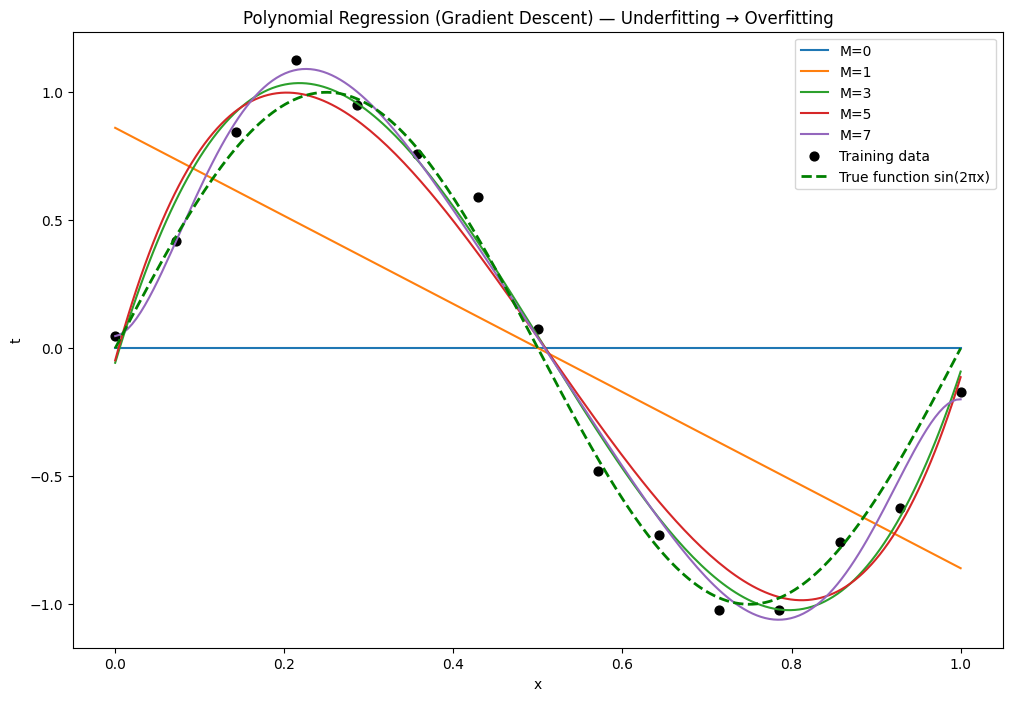

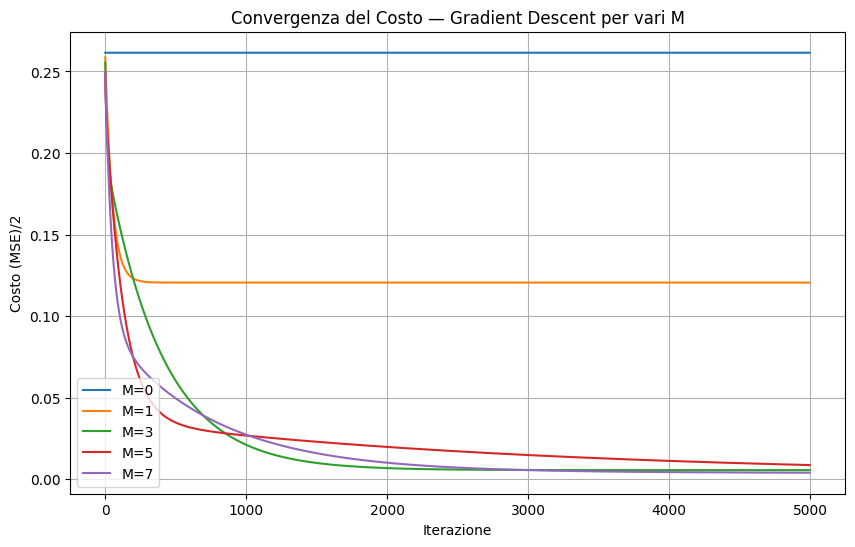

In [ ]:
# %%
# ============================================================
# 3️⃣  POLYNOMIAL FITS (GRADIENT DESCENT VERSION)
# ============================================================
# Per ogni grado M:
#   - costruiamo la matrice di design Φ
#   - addestriamo il modello con discesa del gradiente
#   - salviamo l'andamento del costo
#   - visualizziamo le curve apprese
# ============================================================

degrees = [0, 1, 3, 5, 7]      # diversi gradi di complessità
eta = 0.01                          # learning rate moderato
epochs = 5000                     # numero di iterazioni

plt.figure(figsize=(12, 8))

loss_histories = {}  # per tracciare i costi durante l'addestramento

# ------------------------------------------------------------
# Ciclo sui diversi gradi polinomiali
# ------------------------------------------------------------
for M in degrees:
    # Costruzione della matrice di design
    Phi_train = polynomial_design_matrix(X_train_n, M)

    # Addestramento tramite discesa del gradiente
    w_gd, costs = gradient_descent(Phi_train, t_train, eta=eta, epochs=epochs)

    # Predizioni sul test set
    y_gd = predict(X_test_n, w_gd)

    # Tracciamo la curva appresa
    plt.plot(X_test, y_gd, label=f"M={M}")

    # Salviamo la loss
    loss_histories[M] = costs

# ------------------------------------------------------------
# Dati e funzione vera
# ------------------------------------------------------------
plt.scatter(X_train, t_train, color="black", s=40, label="Training data")
plt.plot(X_test, t_test, "g--", linewidth=2, label="True function sin(2πx)")

plt.legend()
plt.title("Polynomial Regression (Gradient Descent) — Underfitting → Overfitting")
plt.xlabel("x")
plt.ylabel("t")
plt.show()


# ------------------------------------------------------------
# 4️⃣  Andamento della funzione di costo per ogni grado M
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))
for M, costs in loss_histories.items():
    plt.plot(costs, label=f"M={M}")
plt.title("Convergenza del Costo — Gradient Descent per vari M")
plt.xlabel("Iterazione")
plt.ylabel("Costo (MSE)/2")
plt.legend()
plt.grid(True)
plt.show()

---

## ⚙️ Ridge Regression — Soluzione in forma chiusa

La **Ridge Regression** (o **Least Squares regolarizzata**) è un’estensione della regressione lineare classica, pensata per:

1. **Evitare l’overfitting**, specialmente quando il grado del polinomio $M$ è alto.  
2. **Gestire problemi di multicollinearità** (colonne di $\Phi$ quasi dipendenti).  
3. **Stabilizzare la matrice** $(\Phi^\top \Phi)$, rendendola invertibile.

---

### 🔹 1️⃣ Funzione di costo con regolarizzazione L2

A differenza dei minimi quadrati standard, aggiungiamo una penalizzazione sulla norma dei pesi:

$$
E_\lambda(w) = \frac{1}{2n} \| \Phi w - t \|^2 + \frac{\lambda}{2} \| w \|^2
$$

dove:

- $\Phi$ è la matrice di design $(n \times (M+1))$,  
- $w$ è il vettore dei coefficienti,  
- $\lambda > 0$ è il **fattore di regolarizzazione**.  

> Il secondo termine spinge i pesi $w$ a rimanere piccoli, riducendo la complessità del modello.

---

### 🔹 2️⃣ Derivazione del gradiente

Partiamo dal costo:

$$
E_\lambda(w) = \frac{1}{2n}(\Phi w - t)^\top(\Phi w - t) + \frac{\lambda}{2} w^\top w.
$$

Calcoliamo la derivata rispetto a $w$:

$$
\begin{aligned}
\nabla_w E_\lambda(w)
&= \frac{1}{n}\Phi^\top(\Phi w - t) + \lambda w.
\end{aligned}
$$

---

### 🔹 3️⃣ Condizione di minimo

Al minimo, il gradiente è nullo:

$$
\nabla_w E_\lambda(w^\ast) = 0
\quad \Rightarrow \quad
\frac{1}{n}\Phi^\top(\Phi w^\ast - t) + \lambda w^\ast = 0.
$$

Moltiplichiamo per $n$ e riordiniamo:

$$
(\Phi^\top \Phi + n\lambda I) w^\ast = \Phi^\top t.
$$

> In molti testi (come Bishop o Hastie), $\lambda$ viene ridefinito assorbendo il fattore $n$:
>
> $$
> (\Phi^\top \Phi + \lambda I) w^\ast = \Phi^\top t.
> $$

Questa è la **forma chiusa della Ridge Regression**.

---

### 🔹 4️⃣ Soluzione analitica

Risolvendo il sistema lineare otteniamo:

$$
\boxed{
w^\ast = (\Phi^\top \Phi + n \lambda I)^{-1} \Phi^\top t.
}
$$

- Se $\lambda = 0$, si torna ai **minimi quadrati ordinari**.  
- Se $\lambda > 0$, la matrice è **invertibile anche in presenza di collinearità**. La regolarizzazione ne migliora il condizionamento, senza garantire che sia sempre ben condizionata.
- $\lambda$ controlla il *trade-off* bias–varianza:
  - $\lambda$ grande → pesi piccoli, modello rigido (più bias, meno varianza);  
  - $\lambda$ piccolo → modello flessibile, più rischio di overfitting.

---

### 🔹 5️⃣ Interpretazione geometrica

L’aggiunta del termine $\lambda \|w\|^2$ può essere vista come una **penalizzazione**:

- senza regolarizzazione, i pesi $w$ possono crescere molto per adattarsi ai punti rumorosi;  
- con regolarizzazione, il modello è “tirato” verso la soluzione più semplice (pesi piccoli).

---

### 🔹 6️⃣ Effetto pratico nel codice

Nel codice, la riga chiave:

$$
w = (\Phi^\top \Phi + n\lambda I)^{-1} \Phi^\top t
$$

implementa esattamente questa formula.

- `I` è la matrice identità $(M+1) \times (M+1)$,  
- il termine `n * lam * I` regolarizza la diagonale,  
- `np.linalg.solve()` risolve il sistema lineare senza calcolare esplicitamente l'inversa. Con $\lambda > 0$ la matrice è invertibile, anche se può rimanere numericamente mal condizionata.

---

### 💡 In sintesi

| Concetto | Formula | Effetto |
|-----------|----------|---------|
| Funzione di costo | $E_\lambda(w) = \frac{1}{2n}\|\Phi w - t\|^2 + \frac{\lambda}{2}\|w\|^2$ | penalizza pesi grandi |
| Gradiente | $\nabla_w E_\lambda(w) = \frac{1}{n}\Phi^\top(\Phi w - t) + \lambda w$ | aggiunge “forza di richiamo” |
| Equazione normale | $$(\Phi^\top \Phi + n\lambda I)w = \Phi^\top t$$ | sistema lineare regolarizzato |
| Soluzione chiusa | $$w^\ast = (\Phi^\top \Phi + n\lambda I)^{-1}\Phi^\top t$$ | sempre invertibile |
| Effetto di $\lambda$ | ↑ stabilità, ↓ varianza, ↑ bias | controlla la complessità |

---

In pratica, **Ridge Regression** è una versione più robusta dei minimi quadrati:
mantiene le proprietà lineari, ma limita l’ampiezza dei coefficienti, ottenendo modelli più **stabili e generalizzabili**, specialmente con dati rumorosi o feature correlate.

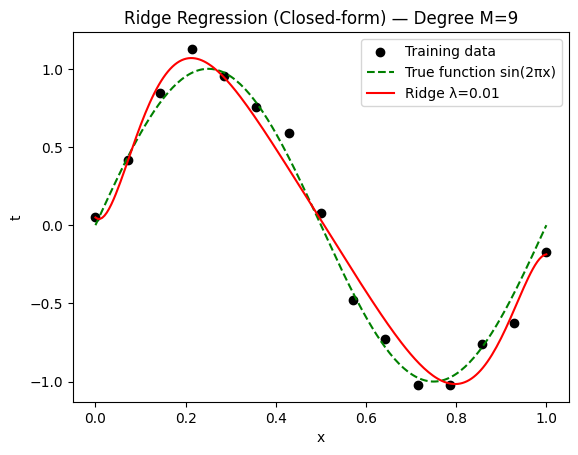

λ = 0.01
MSE (train): 0.0115
MSE (test) : 0.0104


In [ ]:
# %%
# ============================================================
# RIDGE REGRESSION — Closed-form implementation
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error


# ============================================================
# RIDGE REGRESSION — CLOSED-FORM SOLUTION
# ============================================================
# Obiettivo:
#   Risolvere il problema di regressione polinomiale
#   aggiungendo una penalizzazione L2 sui coefficienti.
#
# Funzione obiettivo:
#
#   E(w) = 1/(2n) ||Phi @ w - t||² + (lam/2) ||w||²
#
# Il gradiente è:
#
#   grad E(w) = (Phi.T @ (Phi @ w - t))/n + lam*w
#
# Imponendo grad E(w) = 0 otteniamo:
#
#   (Phi.T @ Phi + n*lam*I) @ w = Phi.T @ t
#
# ATTENZIONE:
#   Il fattore n è necessario perché nella nostra
#   funzione di costo il termine sui dati è mediato
#   sul numero di osservazioni.
#
# In questa implementazione penalizziamo anche il bias,
# rappresentato dal coefficiente w[0].
# ============================================================

def fit_ridge(X, t, M, lam):
    """
    Stima i pesi della Ridge Regression in forma chiusa.

    Parametri:
        X   : input normalizzati, dimensione (n, 1)
        t   : target, dimensione (n, 1)
        M   : grado polinomiale
        lam : coefficiente di regolarizzazione L2

    Restituisce:
        w   : coefficienti stimati, dimensione (M+1, 1)
        Phi : matrice di design, dimensione (n, M+1)

    Interpretazione:
        lam = 0  → Ordinary Least Squares
        lam > 0  → coefficienti penalizzati, soluzione unica

    Nota numerica:
        Usiamo np.linalg.solve anziché calcolare
        esplicitamente l'inversa della matrice.
    """

    # --------------------------------------------------------
    # 1️⃣  Matrice di design e numero di osservazioni
    # --------------------------------------------------------
    Phi = polynomial_design_matrix(X, M)
    n = Phi.shape[0]

    # Il coefficiente di regolarizzazione non può essere
    # negativo nella Ridge Regression standard.
    if lam < 0:
        raise ValueError("lam deve essere maggiore o uguale a zero")

    # --------------------------------------------------------
    # 2️⃣  Caso particolare: nessuna regolarizzazione
    # --------------------------------------------------------
    if lam == 0:

        # Torniamo al problema ai minimi quadrati.
        # lstsq è preferibile quando Phi può essere
        # mal condizionata o non avere rango pieno.
        w = np.linalg.lstsq(Phi, t, rcond=None)[0]

    else:

        # ----------------------------------------------------
        # 3️⃣  Costruzione del sistema Ridge
        # ----------------------------------------------------
        # I introduce una penalizzazione sulla diagonale.
        I = np.eye(Phi.shape[1])

        # Matrice del sistema:
        # A = Phi.T @ Phi + n*lam*I
        A = Phi.T @ Phi + n * lam * I

        # Termine noto:
        # b = Phi.T @ t
        b = Phi.T @ t

        # ----------------------------------------------------
        # 4️⃣  Soluzione del sistema lineare
        # ----------------------------------------------------
        # Risolviamo A @ w = b.
        # Per lam > 0, A è positiva definita.
        w = np.linalg.solve(A, b)

    return w, Phi



# ------------------------------------------------------------
# 1️⃣  Esperimento con M = 9 (modello molto flessibile)
# ------------------------------------------------------------
M = 9
lam = 1e-2  # regolarizzazione moderata

# Fit del modello Ridge
w_ridge, Phi_train = fit_ridge(X_train_n, t_train, M, lam)

# Predizioni
y_ridge_train = predict(X_train_n, w_ridge)
y_ridge_test = predict(X_test_n, w_ridge)

# ------------------------------------------------------------
# 2️⃣  Confronto visivo
# ------------------------------------------------------------
plt.scatter(X_train, t_train, color="black", label="Training data")
plt.plot(X_test, t_test, "g--", label="True function sin(2πx)")
plt.plot(X_test, y_ridge_test, "r", label=f"Ridge λ={lam}")
plt.legend()
plt.title(f"Ridge Regression (Closed-form) — Degree M={M}")
plt.xlabel("x")
plt.ylabel("t")
plt.show()


# ------------------------------------------------------------
# 3️⃣  Valutazione quantitativa
# ------------------------------------------------------------
mse_train = mean_squared_error(t_train, y_ridge_train)
mse_test = mean_squared_error(t_test, y_ridge_test)

print(f"λ = {lam}")
print(f"MSE (train): {mse_train:.4f}")
print(f"MSE (test) : {mse_test:.4f}")

## 🔍 Effetto della regolarizzazione λ in Ridge Regression

In questa sezione osserviamo come la **regolarizzazione L2** (controllata dal parametro λ)  
influenzi il comportamento del modello polinomiale.

- **$\lambda=0$** → si ottiene la regressione ai minimi quadrati ordinari (*Ordinary Least Squares*). Il modello minimizza l'errore sui dati di training, ma non necessariamente li interpola perfettamente.
- **$\lambda$ moderato** → la penalizzazione riduce la grandezza dei coefficienti e può migliorare la ricostruzione del segnale, limitando l'overfitting.
- **$\lambda$ molto grande** → i coefficienti tendono a zero e il modello rischia l'underfitting. Poiché in questa implementazione penalizziamo anche il bias, la funzione predetta tende alla funzione nulla.

**Attenzione:** una regolarizzazione più forte non garantisce sempre una migliore ricostruzione. Un valore eccessivo di $\lambda$ introduce troppo bias.

📈 In questo esperimento visualizziamo l’effetto di diversi valori di λ,  
mantenendo fisso il grado polinomiale $M=9$.

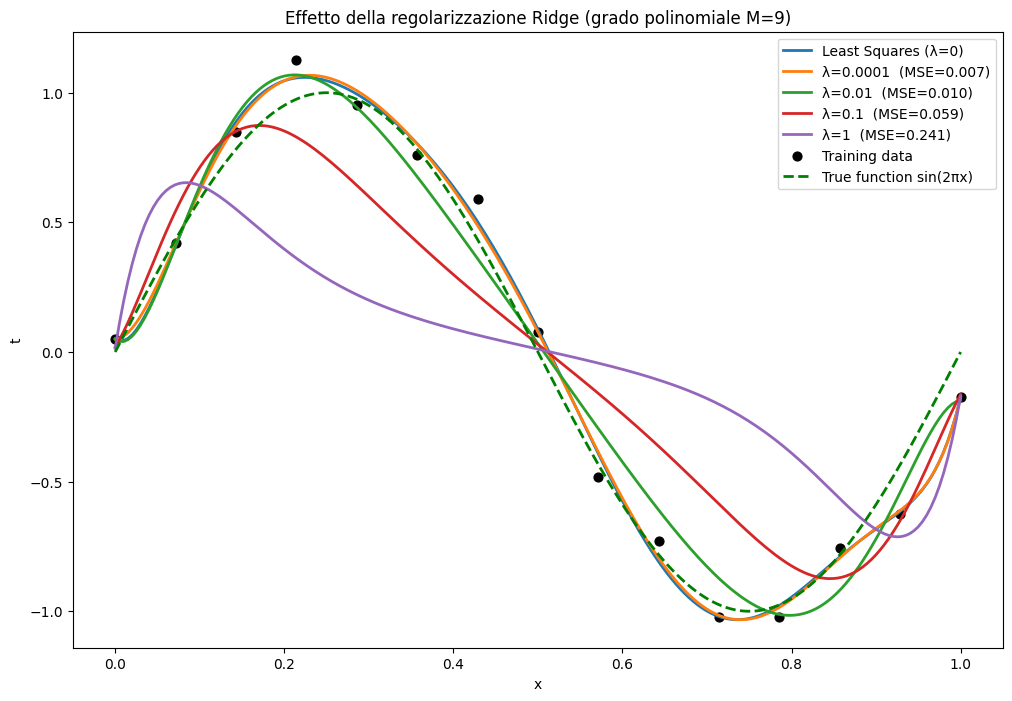

In [ ]:
# %%
# ============================================================
# RIDGE REGRESSION — Effetto della regolarizzazione λ
# ============================================================

from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# Parametri di esperimento
M = 9                         # grado polinomiale elevato → alto rischio di overfitting
lambdas = [0, 1e-4, 1e-2, 1e-1, 1]   # diversi livelli di regolarizzazione

plt.figure(figsize=(12, 8))

# ------------------------------------------------------------
# Ciclo sui diversi valori di λ
# ------------------------------------------------------------
for lam in lambdas:
    # Fit del modello Ridge (λ = 0 equivale ai minimi quadrati)
    w_ridge, Phi_train_ridge = fit_ridge(X_train_n, t_train, M, lam)
    y_ridge_test = predict(X_test_n, w_ridge)

    # Calcolo dell'errore sul test set
    mse_test = mean_squared_error(t_test, y_ridge_test)

    # Tracciamento della curva
    label = f"λ={lam}  (MSE={mse_test:.3f})" if lam > 0 else f"Least Squares (λ=0)"
    plt.plot(X_test, y_ridge_test, linewidth=2, label=label)

# ------------------------------------------------------------
# Dati e funzione vera
# ------------------------------------------------------------
plt.scatter(X_train, t_train, color="black", s=40, label="Training data")
plt.plot(X_test, t_test, "g--", linewidth=2, label="True function sin(2πx)")

plt.title(f"Effetto della regolarizzazione Ridge (grado polinomiale M={M})")
plt.xlabel("x")
plt.ylabel("t")
plt.legend()
plt.show()

## Ridge via Gradient Descent

## ⚙️ Ridge Regression — Gradient Descent Implementation
In questa sezione implementiamo la **Ridge Regression** in forma **iterativa**,
utilizzando la **Discesa del Gradiente batch (Batch Gradient Descent)**,  
invece della classica soluzione chiusa dei minimi quadrati regolarizzati.

---

### 🔹 1️⃣ Funzione di costo regolarizzata

La funzione di costo Ridge combina due termini:

$$
E_\lambda(w) = \frac{1}{2n}\|\Phi w - t\|^2 + \frac{\lambda}{2}\|w\|^2
$$

- **Errore di ricostruzione**: misura quanto bene il modello approssima i dati  
- **Penalità L2**: riduce i pesi troppo grandi, controllando la complessità del modello  

La Ridge, infatti, tende a preferire soluzioni “piccole” ma stabili.

---

### 🔹 2️⃣ Discesa del gradiente batch

Il gradiente della funzione di costo è:

$$
\nabla_w E_\lambda(w) = \frac{1}{n}\Phi^\top(\Phi w - t) + \lambda w
$$

e l’aggiornamento dei pesi ad ogni iterazione è:

$$
w \leftarrow w - \eta \, \nabla_w E_\lambda(w)
$$

dove:
- $ \eta $ è il **learning rate**,  
- $ \lambda $ controlla la **forza della regolarizzazione**.  

Dopo un numero sufficiente di epoche, $w$ converge al valore ottimo che minimizza $E_\lambda(w)$ (equivalente alla soluzione chiusa della Ridge).

---

### 🔹 3️⃣ Interpretazione dei risultati

- Il grafico del costo $E_\lambda(w)$ decresce gradualmente fino a stabilizzarsi → **convergenza**.  
- La curva appresa (linea rossa) è **più regolare** della regressione ai minimi quadrati puri:  
  la regolarizzazione $\lambda$ ha effettivamente ridotto l’overfitting.  
- All’aumentare di $\lambda$, i pesi si contraggono e la curva diventa più liscia.

---

### 🔹 4️⃣ Metrica di valutazione

Infine, confrontiamo il MSE sui dati di training con l'errore di ricostruzione della funzione vera sulla nostra griglia sintetica di valutazione.

- MSE basso su entrambi → buon fit generalizzante  
- MSE basso su train ma alto su test → *overfitting*  
- MSE alto su entrambi → *underfitting*

---

### 💡 In sintesi

| Concetto | Formula | Effetto |
|-----------|----------|---------|
| Costo Ridge | $$E_\lambda(w) = \tfrac{1}{2n}\|\Phi w - t\|^2 + \tfrac{\lambda}{2}\|w\|^2$$ | Penalizza pesi grandi |
| Gradiente | $$\nabla_w E_\lambda(w) = \tfrac{1}{n}\Phi^\top(\Phi w - t) + \lambda w$$ | Direzione di discesa |
| Aggiornamento | $w \leftarrow w - \eta \nabla_w E_\lambda(w)$ | Passo iterativo verso il minimo |
| Risultato | MSE più basso e curva più liscia | Migliore generalizzazione |

---

📈 **Osservazione finale**

La Ridge Regression può essere risolta sia analiticamente sia tramite Gradient Descent.

I due approcci minimizzano la stessa funzione obiettivo: il primo risolve un sistema lineare, mentre il secondo si avvicina progressivamente alla soluzione ottima.

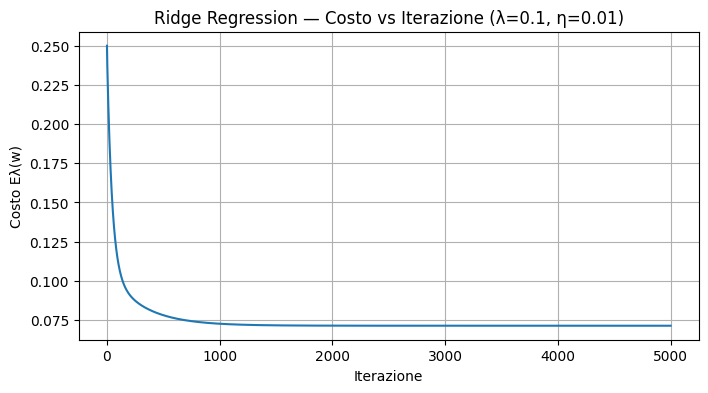

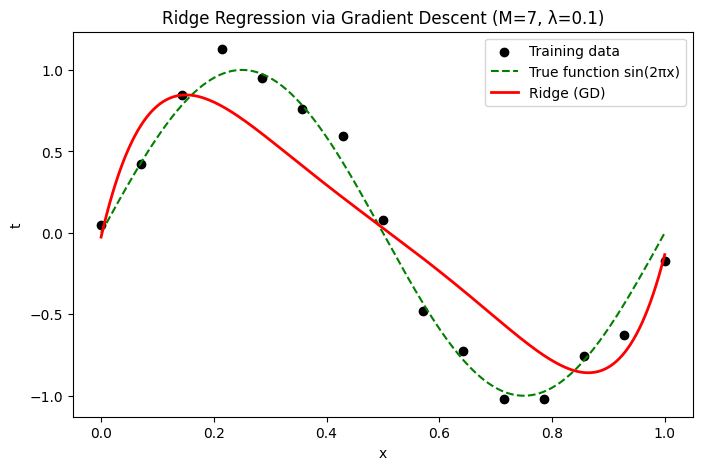

MSE train: 0.0745
MSE test : 0.0723


In [ ]:
# %%
# ============================================================
# RIDGE REGRESSION — Gradient Descent Implementation
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# ------------------------------------------------------------
# 1️⃣  Funzione di costo e gradiente
# ------------------------------------------------------------
def cost_ridge(Phi, w, t, lam):
    """
    Funzione di costo regolarizzata (Ridge):
        Eλ(w) = 1/(2n) * ||Φw - t||² + (λ/2) * ||w||²
    """
    r = Phi @ w - t
    mse_term = 0.5 * np.mean(r**2)
    reg_term = 0.5 * lam * np.sum(w**2)
    return mse_term + reg_term


def grad_ridge(Phi, w, t, lam):
    """
    Gradiente della funzione di costo Ridge:
        ∇Eλ(w) = (1/n) * Φᵀ(Φw - t) + λw
    """
    r = Phi @ w - t
    return (Phi.T @ r) / len(t) + lam * w


# ------------------------------------------------------------
# 2️⃣  Discesa del gradiente batch
# ------------------------------------------------------------

# ============================================================
# RIDGE REGRESSION — BATCH GRADIENT DESCENT
# ============================================================
# Obiettivo:
#   Minimizzare iterativamente la funzione Ridge.
# ============================================================

def gradient_descent_ridge(
    Phi, t, lam=1e-2, eta=1e-2, epochs=3000
):
    """
    Esegue Gradient Descent batch sulla funzione Ridge.

    Funzione obiettivo:
        E(w) = 1/(2n) ||Phi @ w - t||²
               + lam/2 ||w||²

    Parametri:
        Phi       : matrice di design
        t         : vettore dei target
        lam       : intensità della regolarizzazione L2
        eta       : learning rate
        epochs    : numero di aggiornamenti

    Restituisce:
        w     : coefficienti finali
        costs : storia della funzione obiettivo
    """

    # --------------------------------------------------------
    # 1️⃣  Inizializzazione
    # --------------------------------------------------------
    w = np.zeros((Phi.shape[1], 1))
    costs = []

    # --------------------------------------------------------
    # 2️⃣  Ciclo di ottimizzazione
    # --------------------------------------------------------
    for _ in range(epochs):

        # Calcoliamo il gradiente Ridge su tutto il dataset
        g = grad_ridge(Phi, w, t, lam)

        # ----------------------------------------------------
        # Aggiornamento dei coefficienti
        # ----------------------------------------------------
        w -= eta * g

        # ----------------------------------------------------
        # 6️⃣  Memorizzazione della funzione di costo
        # ----------------------------------------------------
        costs.append(cost_ridge(Phi, w, t, lam))

    return w, costs



# ------------------------------------------------------------
# 3️⃣  Esperimento: confronto visivo e andamento della loss
# ------------------------------------------------------------
M = 7         # grado polinomiale
lam = 0.1     # regolarizzazione
eta = 0.01    # learning rate
epochs = 5000 # numero di iterazioni

# Matrice di design
Phi_train = polynomial_design_matrix(X_train_n, M)

# Addestramento con discesa del gradiente Ridge
w_ridge_gd, costs = gradient_descent_ridge(Phi_train, t_train, lam, eta, epochs)

# Predizioni su train e test
y_ridge_train = predict(X_train_n, w_ridge_gd)
y_ridge_test  = predict(X_test_n, w_ridge_gd)

# ------------------------------------------------------------
# 4️⃣  Grafico della funzione di costo
# ------------------------------------------------------------
plt.figure(figsize=(8,4))
plt.plot(costs)
plt.title(f"Ridge Regression — Costo vs Iterazione (λ={lam}, η={eta})")
plt.xlabel("Iterazione")
plt.ylabel("Costo Eλ(w)")
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# 5️⃣  Confronto visivo del fit
# ------------------------------------------------------------
plt.figure(figsize=(8,5))
plt.scatter(X_train, t_train, color="black", label="Training data")
plt.plot(X_test, t_test, "g--", label="True function sin(2πx)")
plt.plot(X_test, y_ridge_test, "r", linewidth=2, label="Ridge (GD)")
plt.legend()
plt.title(f"Ridge Regression via Gradient Descent (M={M}, λ={lam})")
plt.xlabel("x")
plt.ylabel("t")
plt.show()

# ------------------------------------------------------------
# 6️⃣  Valutazione numerica
# ------------------------------------------------------------
mse_train = mean_squared_error(t_train, y_ridge_train)
mse_test  = mean_squared_error(t_test, y_ridge_test)
print(f"MSE train: {mse_train:.4f}")
print(f"MSE test : {mse_test:.4f}")

## ⚙️ Lasso Regression — Regolarizzazione L1

Finora abbiamo visto che la **Ridge Regression** limita la grandezza dei coefficienti introducendo una penalizzazione L2:

$$
E_{\text{Ridge}}(w)
=
\frac{1}{2n}\|\Phi w-t\|^2
+
\frac{\lambda}{2}\sum_{j=0}^{M}w_j^2.
$$

La **Lasso Regression** segue la stessa idea, ma utilizza una penalizzazione diversa: invece di sommare i quadrati dei coefficienti, somma i loro valori assoluti.

$$
\boxed{
E_{\text{Lasso}}(w)
=
\frac{1}{2n}\|\Phi w-t\|^2
+
\lambda\sum_{j=0}^{M}|w_j|
}
$$

Anche qui, $\lambda$ controlla l'intensità della regolarizzazione.

### 🔹 Qual è la differenza rispetto a Ridge?

- **Ridge (L2)** tende a rendere i coefficienti più piccoli, ma generalmente non li annulla.
- **Lasso (L1)** può portare alcuni coefficienti esattamente a zero.

Ad esempio, supponiamo di utilizzare un polinomio di grado 5:

$$
h(x)=w_0+w_1x+w_2x^2+w_3x^3+w_4x^4+w_5x^5.
$$

Con Ridge, potremmo ottenere coefficienti tutti diversi da zero, anche se alcuni molto piccoli.

Con Lasso, invece, alcuni coefficienti potrebbero annullarsi, producendo ad esempio:

$$
h(x)=w_0+w_1x+w_3x^3.
$$

In questo caso, le feature $x^2$, $x^4$ e $x^5$ non contribuiscono più alla predizione.

Questa proprietà si chiama **sparsità** (*sparsity*): Lasso può quindi effettuare una forma di **selezione automatica delle feature**.

### 🔹 Perché Lasso può annullare i coefficienti?

La penalizzazione L2 è una funzione liscia, mentre il valore assoluto utilizzato da Lasso presenta un punto angoloso in zero.

Questa caratteristica favorisce soluzioni in cui alcuni coefficienti sono esattamente nulli.

A differenza di Ridge, Lasso non ammette in generale una semplice soluzione analitica tramite le equazioni normali: si utilizzano metodi di ottimizzazione specifici.

### 💡 In sintesi

| Ridge (L2) | Lasso (L1) |
|---|---|
| Penalizza i quadrati dei coefficienti | Penalizza i valori assoluti |
| Riduce la grandezza dei pesi | Può annullare alcuni pesi |
| Mantiene generalmente tutte le feature | Può selezionare un sottoinsieme di feature |
| Ammette una soluzione analitica | Si risolve generalmente con metodi iterativi |

**Nel prossimo esperimento utilizzeremo scikit-learn per confrontare Ridge e Lasso**, osservando sia le curve apprese sia i coefficienti stimati.

In particolare, verificheremo se Lasso riesce ad annullare alcuni coefficienti del nostro modello polinomiale.

## 🧰 Regressione lineare con *scikit-learn*

Finora abbiamo derivato e implementato a mano:

- la **regressione ai minimi quadrati**;
- la **Ridge Regression** (regolarizzazione L2).

Abbiamo inoltre introdotto la **Lasso Regression** (regolarizzazione L1), che implementeremo come esercizio finale.

Tutti questi modelli sono disponibili direttamente nella libreria **`scikit-learn`**,  
che fornisce implementazioni ottimizzate e numericamente stabili.

Vediamo come usare:
- `LinearRegression` → minimi quadrati standard,  
- `Ridge` → regressione L2,  
- `Lasso` → regressione L1.

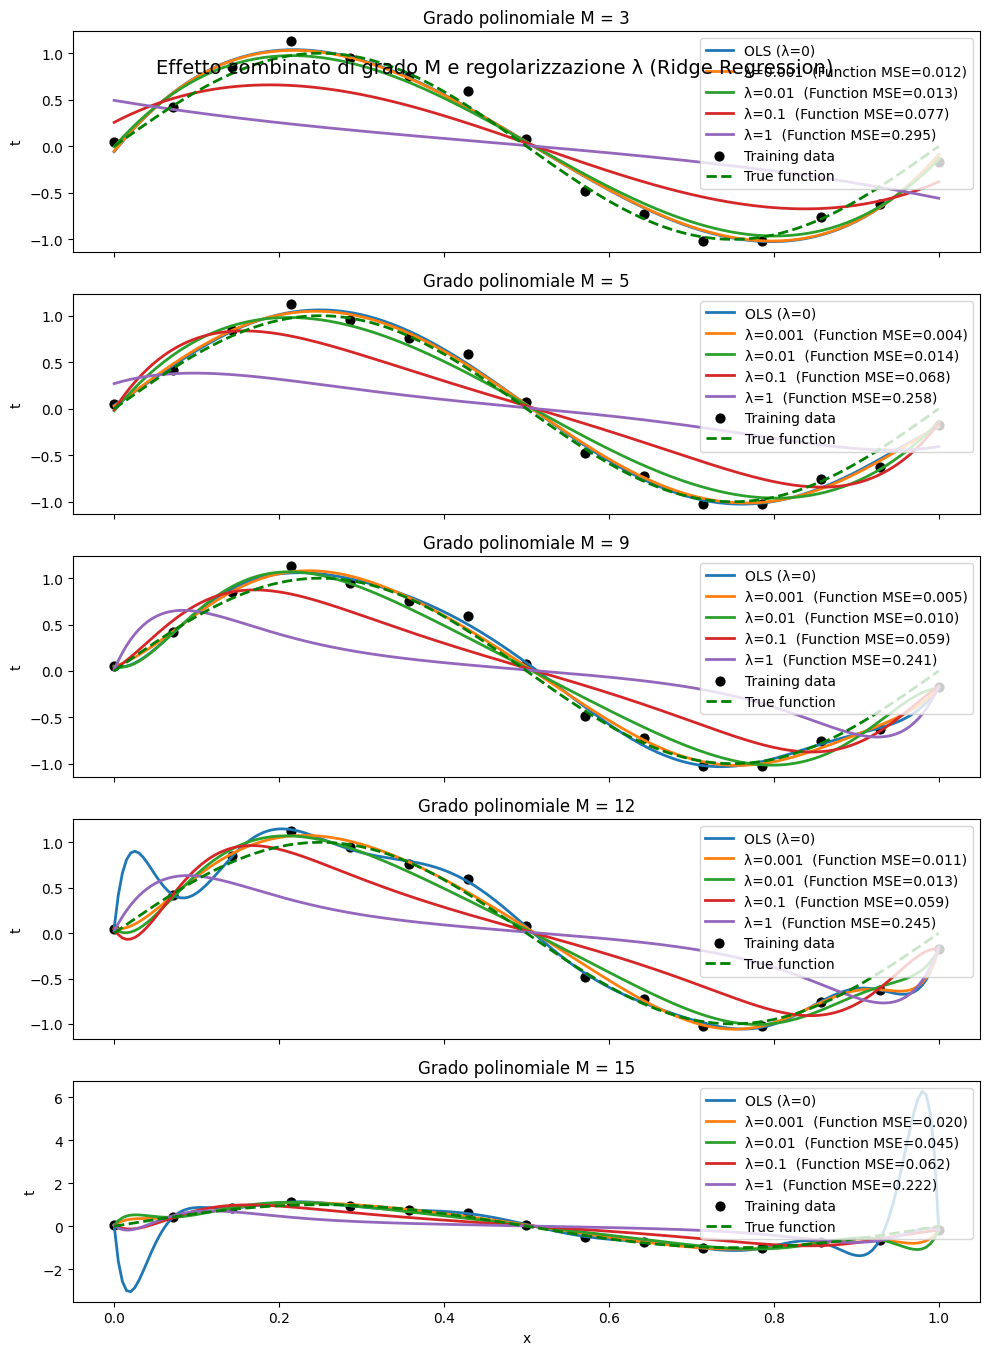

=== Mean Squared Error (MSE) ===

Grado polinomiale M = 3
λ		Train MSE	Function MSE
----------------------------------------
0       	0.0112		0.0120
0.001   	0.0112		0.0119
0.01    	0.0133		0.0130
0.1     	0.0871		0.0772
1       	0.3211		0.2950

Grado polinomiale M = 5
λ		Train MSE	Function MSE
----------------------------------------
0       	0.0042		0.0038
0.001   	0.0044		0.0041
0.01    	0.0142		0.0140
0.1     	0.0707		0.0678
1       	0.2751		0.2578

Grado polinomiale M = 9
λ		Train MSE	Function MSE
----------------------------------------
0       	0.0024		0.0075
0.001   	0.0035		0.0054
0.01    	0.0115		0.0104
0.1     	0.0628		0.0586
1       	0.2451		0.2410

Grado polinomiale M = 12
λ		Train MSE	Function MSE
----------------------------------------
0       	0.0005		0.0339
0.001   	0.0030		0.0114
0.01    	0.0093		0.0126
0.1     	0.0613		0.0591
1       	0.2463		0.2448

Grado polinomiale M = 15
λ		Train MSE	Function MSE
----------------------------------------
0       	0.0000		1.5126
0

In [ ]:
# ============================================================
# RIDGE REGRESSION — Effetto combinato di grado M e regolarizzazione λ
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# Gradi polinomiali da esplorare
degrees = [3, 5, 9, 12, 15]
# Diversi valori di regolarizzazione
lambdas = [0, 1e-3, 1e-2, 1e-1, 1]

# Creazione dei subplot (una riga per ogni M)
fig, axes = plt.subplots(len(degrees), 1, figsize=(10, 14), sharex=True)

# Dizionario per salvare i risultati numerici
mse_results = {}

for i, M in enumerate(degrees):
    ax = axes[i]
    Phi_train = polynomial_design_matrix(X_train_n, M)
    Phi_test = polynomial_design_matrix(X_test_n, M)
    mse_results[M] = {}

    for lam in lambdas:
        # ----------------------------------------------------
        # 🔹 Ridge Regression tramite scikit-learn
        # ----------------------------------------------------
        # Nel nostro laboratorio abbiamo definito:
        #
        # E(w) = 1/(2n) ||Phi @ w - t||²
        #        + lam/2 ||w||²
        #
        # scikit-learn utilizza invece la convenzione:
        #
        # ||Phi @ w - t||² + alpha ||w||²
        #
        # Per ottenere lo stesso problema matematico:
        #
        #     alpha = n * lam
        #
        # fit_intercept=False:
        #   La colonna di 1 è già presente nella design
        #   matrix e rappresenta il bias.
        #
        # solver="svd":
        #   Utilizza una decomposizione numericamente
        #   robusta, utile con feature polinomiali correlate.

        ridge = Ridge(
            alpha=len(t_train) * lam,
            fit_intercept=False,
            solver="svd"
        )

        ridge.fit(Phi_train, t_train)

        # Predizioni
        y_train_pred = ridge.predict(Phi_train)
        y_test_pred = ridge.predict(Phi_test)

        # Calcolo MSE su train e test
        mse_train = mean_squared_error(t_train, y_train_pred)
        mse_test = mean_squared_error(t_test, y_test_pred)

        mse_results[M][lam] = (mse_train, mse_test)

        # Traccia le curve
        label = f"λ={lam}  (Function MSE={mse_test:.3f})" if lam > 0 else "OLS (λ=0)"
        ax.plot(X_test, y_test_pred, linewidth=2, label=label)

    # Dati e funzione vera
    ax.scatter(X_train, t_train, color="black", s=40, label="Training data")
    ax.plot(X_test, t_test, "g--", linewidth=2, label="True function")

    ax.set_title(f"Grado polinomiale M = {M}")
    ax.set_ylabel("t")
    ax.legend()

plt.xlabel("x")
plt.suptitle("Effetto combinato di grado M e regolarizzazione λ (Ridge Regression)", fontsize=14, y=0.93)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Stampa tabellare dei MSE per ogni combinazione (M, λ)
# ------------------------------------------------------------
print("=== Mean Squared Error (MSE) ===")
for M in degrees:
    print(f"\nGrado polinomiale M = {M}")
    print("λ\t\tTrain MSE\tFunction MSE")
    print("-"*40)
    for lam, (mse_train, mse_test) in mse_results[M].items():
        print(f"{lam:<8g}\t{mse_train:.4f}\t\t{mse_test:.4f}")

### 📊 Analisi dei risultati

Il grado polinomiale $M$ controlla la flessibilità del modello, mentre il parametro $\lambda$ controlla la forza della penalizzazione Ridge.

Osserviamo che:

- con gradi bassi il modello può essere troppo semplice per ricostruire la sinusoide;
- con gradi elevati e poca regolarizzazione il modello può adattarsi al rumore;
- una regolarizzazione adeguata può migliorare la ricostruzione;
- una regolarizzazione eccessiva produce underfitting.

**Non esiste un valore di $\lambda$ universalmente ottimale:** il risultato dipende anche dal grado del polinomio e dal dataset.

Nel nostro esperimento possiamo confrontare direttamente le predizioni con la sinusoide vera. In un problema reale, invece, sceglieremmo $M$ e $\lambda$ su un validation set o mediante cross-validation.

In [ ]:

# ============================================================
# Migliore combinazione (M, lambda) sulla funzione vera
# Solo a scopo didattico: in un problema reale si usa validation
# ============================================================

risultati = []

for M, valori in mse_results.items():
    for lam, (mse_train, mse_function) in valori.items():
        risultati.append((M, lam, mse_train, mse_function))

risultati.sort(key=lambda r: r[3])

print("Le 5 combinazioni migliori sulla griglia sintetica:")
print("M     lambda       Train MSE      Function MSE")
print("-" * 52)

for M, lam, mse_train, mse_function in risultati[:5]:
    print(
        f"{M:<5d} {lam:<12g} "
        f"{mse_train:<14.6f} {mse_function:.6f}"
    )


Le 5 combinazioni migliori sulla griglia sintetica:
M     lambda       Train MSE      Function MSE
----------------------------------------------------
5     0            0.004164       0.003849
5     0.001        0.004391       0.004121
9     0.001        0.003481       0.005378
9     0            0.002417       0.007511
9     0.01         0.011538       0.010415


## ⚙️ Lasso Regression — Regolarizzazione L1 e Sparsità

Finora abbiamo osservato che **Ridge Regression** riduce la grandezza dei coefficienti aggiungendo una penalizzazione L2.

Ora introduciamo **Lasso Regression**, che utilizza invece una penalizzazione L1:

$$
E_\lambda(w)
=
\frac{1}{2n}\|\Phi w-t\|^2
+
\lambda\sum_{j=0}^{M}|w_j|.
$$

La differenza principale è che:

- **Ridge (L2)** tende a rendere piccoli i coefficienti, ma generalmente non li annulla.
- **Lasso (L1)** può portare alcuni coefficienti esattamente a zero.

Questo significa che Lasso può effettuare una forma di **selezione automatica delle feature**.

---

### 🎯 Obiettivo dell'esperimento

Utilizziamo la stessa matrice di design polinomiale per confrontare Ridge e Lasso, mantenendo fisso il grado del polinomio.

Vogliamo osservare:

1. Come cambiano le curve apprese.
2. Come cambiano i coefficienti del modello.
3. Quanti coefficienti vengono annullati da Lasso.
4. Quale modello ricostruisce meglio la sinusoide vera.

---

### 💡 Perché Lasso può produrre coefficienti nulli?

La penalizzazione L2 è una funzione liscia dei coefficienti e tende a ridurli progressivamente.

La penalizzazione L1 contiene invece il valore assoluto, che presenta un punto angoloso in zero.

Questa proprietà può rendere conveniente annullare completamente alcuni coefficienti.

**Attenzione:** questo non significa che Lasso individui sempre le feature realmente importanti. Con feature fortemente correlate, come le potenze polinomiali, la selezione può essere instabile.

---

### 🔍 Cosa osservare nei grafici

Nel primo grafico confrontiamo le predizioni di Ridge e Lasso con la funzione sinusoidale originale.

Nel secondo grafico confrontiamo direttamente i coefficienti stimati.

**L'osservazione fondamentale è che Ridge riduce i coefficienti, mentre Lasso può eliminarne alcuni.**

Per il confronto utilizziamo `fit_intercept=False`, perché la matrice polinomiale contiene già la colonna costante. In questo esperimento penalizziamo anche il bias, per mantenere la stessa convenzione del resto del laboratorio.

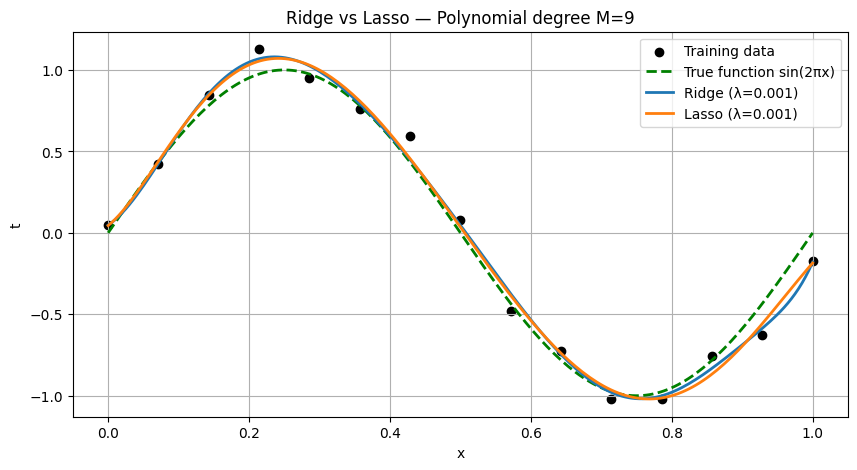

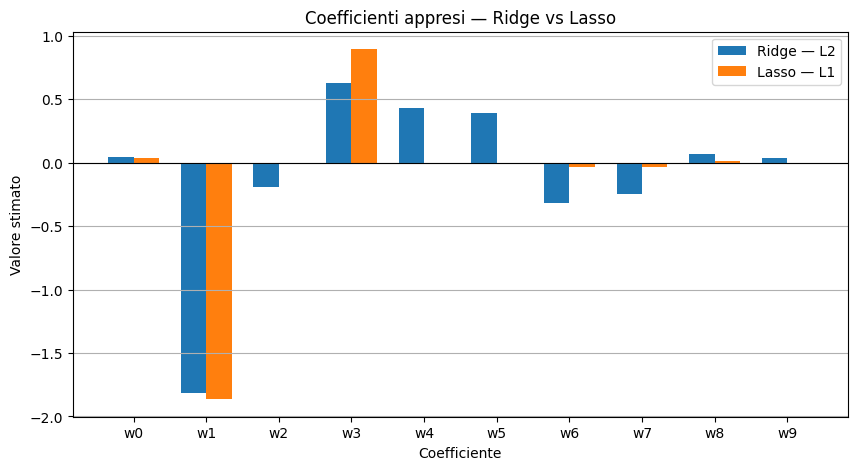

=== Ridge vs Lasso ===
Grado polinomiale M = 9
Regolarizzazione λ = 0.001
---------------------------------------
Ridge — Function MSE: 0.005378
Lasso — Function MSE: 0.004249
---------------------------------------
Coefficienti nulli in Lasso: 4 su 10

Coefficienti Ridge:
[ 0.04706  -1.813766 -0.191595  0.631017  0.429708  0.394345 -0.318721
 -0.245946  0.067273  0.038303]

Coefficienti Lasso:
[ 0.035371 -1.864107  0.        0.894535  0.        0.       -0.033328
 -0.030674  0.010472 -0.      ]


In [ ]:

# ============================================================
# LASSO VS RIDGE — REGULARIZATION AND SPARSITY
# ============================================================
# Obiettivo:
#   Confrontare due forme di regolarizzazione:
#
#   Ridge → penalizzazione L2
#   Lasso → penalizzazione L1
#
# Utilizziamo lo stesso dataset e lo stesso grado
# polinomiale per isolare l'effetto della penalizzazione.
#
# Osserveremo:
#   1. Le curve apprese dai due modelli.
#   2. L'errore rispetto alla funzione vera.
#   3. I coefficienti stimati.
#   4. La sparsità introdotta da Lasso.
# ============================================================

from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error

# ------------------------------------------------------------
# 1️⃣  Parametri dell'esperimento
# ------------------------------------------------------------

# Utilizziamo un grado elevato per introdurre molte feature
# polinomiali e rendere significativa la regolarizzazione.
M = 9

# Intensità della penalizzazione.
# La conversione di alpha rende coerenti le convenzioni
# matematiche con quelle definite nel laboratorio.
# Lo stesso lambda non implica una penalizzazione
# di intensità equivalente tra Ridge e Lasso.
lam = 1e-3

# ------------------------------------------------------------
# 2️⃣  Costruzione delle matrici di design
# ------------------------------------------------------------

Phi_train = polynomial_design_matrix(X_train_n, M)
Phi_test = polynomial_design_matrix(X_test_n, M)

# ------------------------------------------------------------
# 3️⃣  Modello Ridge — Penalizzazione L2
# ------------------------------------------------------------
# Obiettivo:
#
#   1/(2n) ||Phi @ w - t||² + lam/2 ||w||²
#
# Ridge riduce i coefficienti, ma generalmente non
# ne produce molti esattamente nulli.
#
# Per scikit-learn:
#     alpha = n * lam

ridge = Ridge(
    alpha=len(t_train) * lam,
    fit_intercept=False,
    solver="svd"
)

# ------------------------------------------------------------
# 4️⃣  Modello Lasso — Penalizzazione L1
# ------------------------------------------------------------
# Obiettivo:
#
#   1/(2n) ||Phi @ w - t||² + lam * ||w||_1
#
# La penalizzazione L1 può annullare alcuni coefficienti.
#
# max_iter elevato:
#   Utile perché le feature polinomiali possono essere
#   fortemente correlate e rallentare la convergenza.
#
# tol piccolo:
#   Richiediamo una soluzione numericamente accurata.

lasso = Lasso(
    alpha=lam,
    fit_intercept=False,
    max_iter=200000,
    tol=1e-8
)

# ------------------------------------------------------------
# 5️⃣  Addestramento dei modelli
# ------------------------------------------------------------

# scikit-learn richiede qui un target monodimensionale.
ridge.fit(Phi_train, t_train.ravel())
lasso.fit(Phi_train, t_train.ravel())

# ------------------------------------------------------------
# 6️⃣  Predizioni sulla griglia di valutazione
# ------------------------------------------------------------

y_ridge = ridge.predict(Phi_test)
y_lasso = lasso.predict(Phi_test)

# ------------------------------------------------------------
# 7️⃣  Confronto visivo delle curve apprese
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

# Osservazioni rumorose utilizzate per l'addestramento
plt.scatter(
    X_train, t_train,
    color="black",
    label="Training data"
)

# Funzione generatrice, nota soltanto nel nostro
# esperimento sintetico
plt.plot(
    X_test, t_test,
    "g--",
    linewidth=2,
    label="True function sin(2πx)"
)

# Predizione Ridge
plt.plot(
    X_test, y_ridge,
    linewidth=2,
    label=f"Ridge (λ={lam})"
)

# Predizione Lasso
plt.plot(
    X_test, y_lasso,
    linewidth=2,
    label=f"Lasso (λ={lam})"
)

plt.title(f"Ridge vs Lasso — Polynomial degree M={M}")
plt.xlabel("x")
plt.ylabel("t")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# 8️⃣  Confronto dei coefficienti
# ------------------------------------------------------------
# Ogni colonna della design matrix corrisponde a una
# funzione di base:
#
#   1, x, x², ..., x^M
#
# Confrontiamo il valore assegnato a ciascuna funzione.
# In particolare cerchiamo coefficienti che Lasso
# porta esattamente a zero.

coeff_indices = np.arange(M + 1)
bar_width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    coeff_indices - bar_width / 2,
    ridge.coef_,
    width=bar_width,
    label="Ridge — L2"
)

plt.bar(
    coeff_indices + bar_width / 2,
    lasso.coef_,
    width=bar_width,
    label="Lasso — L1"
)

plt.axhline(0, color="black", linewidth=0.8)

plt.xticks(
    coeff_indices,
    [f"w{j}" for j in coeff_indices]
)

plt.title("Coefficienti appresi — Ridge vs Lasso")
plt.xlabel("Coefficiente")
plt.ylabel("Valore stimato")
plt.legend()
plt.grid(True, axis="y")
plt.show()

# ------------------------------------------------------------
# 9️⃣  Valutazione quantitativa
# ------------------------------------------------------------
# Poiché conosciamo la funzione generatrice, misuriamo
# la MSE rispetto alla sinusoide vera, senza rumore.
#
# Questa misura descrive la qualità della ricostruzione
# del segnale, non la loss su nuovi target rumorosi.

mse_ridge = mean_squared_error(
    t_test.ravel(), y_ridge
)

mse_lasso = mean_squared_error(
    t_test.ravel(), y_lasso
)

print("=== Ridge vs Lasso ===")
print(f"Grado polinomiale M = {M}")
print(f"Regolarizzazione λ = {lam}")
print("---------------------------------------")
print(f"Ridge — Function MSE: {mse_ridge:.6f}")
print(f"Lasso — Function MSE: {mse_lasso:.6f}")

# ------------------------------------------------------------
# 🔟  Misura della sparsità
# ------------------------------------------------------------
# Contiamo quanti coefficienti Lasso ha portato
# a zero, entro una piccola tolleranza numerica.
#
# Una soluzione più sparsa utilizza meno funzioni
# di base nella rappresentazione del predittore.

zero_coefficients = np.sum(
    np.abs(lasso.coef_) < 1e-8
)

print("---------------------------------------")
print(
    f"Coefficienti nulli in Lasso: "
    f"{zero_coefficients} su {M + 1}"
)

print("\nCoefficienti Ridge:")
print(np.round(ridge.coef_, 6))

print("\nCoefficienti Lasso:")
print(np.round(lasso.coef_, 6))



## 🧪 Esercizio finale — Implementare Lasso Regression

Finora abbiamo implementato la regressione ai minimi quadrati e la Ridge Regression utilizzando Gradient Descent.

Ora proviamo a implementare **Lasso Regression**, modificando il codice già visto.

### 🎯 Obiettivo

Lasso utilizza una penalizzazione L1, cioè la somma dei valori assoluti dei coefficienti:

$$
E(w) = \frac{1}{2n}\|\Phi w-t\|^2
       + \lambda\sum_{j=0}^{M}|w_j|
$$

La differenza principale è che:

- **Ridge (L2)** penalizza i quadrati dei coefficienti.
- **Lasso (L1)** penalizza i valori assoluti dei coefficienti.

### 🔹 Come implementarla?

Il valore assoluto non è derivabile in zero. Possiamo però utilizzare un **subgradiente**.

Nel nostro esercizio scegliamo:

$$
g = \frac{1}{n}\Phi^\top(\Phi w-t)
    + \lambda\,\operatorname{sign}(w)
$$

dove `np.sign(w)` restituisce:

- `+1` se il coefficiente è positivo;
- `-1` se il coefficiente è negativo;
- `0` se il coefficiente è zero.

### 💻 Completate il codice

```python
def grad_lasso(Phi, w, t, lam):

    # TODO 1: gradiente della loss quadratica
    g_data = ...

    # TODO 2: subgradiente della penalizzazione L1
    g_reg = ...

    return g_data + g_reg


def gradient_descent_lasso(Phi, t, lam=0.001,
                           eta=0.001, epochs=10000):

    w = np.zeros((Phi.shape[1], 1))

    for _ in range(epochs):

        # TODO 3: calcolare il subgradiente
        g = ...

        # TODO 4: aggiornare i coefficienti
        w = ...

    return w
```

### 🔍 Esperimento

1. Utilizzate il dataset sinusoidale del laboratorio.
2. Costruite un modello polinomiale di grado **M = 5**.
3. Addestrate il modello con la vostra implementazione.
4. Confrontate i coefficienti ottenuti con quelli di Ridge.
5. Ripetete l'esperimento aumentando il valore di $\lambda$.

### ❓ Domanda finale

**Come cambiano i coefficienti aumentando $\lambda$?**

Qual è la differenza tra la penalizzazione L1 e la penalizzazione L2?

> **Nota:** questo esercizio utilizza il *Subgradient Descent*, una versione didattica e semplificata dell'ottimizzazione di Lasso. A differenza degli algoritmi specifici come il *Proximal Gradient Descent*, non garantisce coefficienti esattamente nulli.
